In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import scipy

datapath = "../week6/collected_data_spring_2.csv"

df = pd.read_csv(datapath)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

print(df.shape)

MAX_REPLICA_COUNT = df['Count'].max() + 1

replica_graphs = []

def get_replica_row(replica_num, group):
    if len(group) >= replica_num:
        return group.iloc[replica_num-1:replica_num]

grouped = df.groupby('Timestamp')

node_stats = grouped.apply(lambda x: x.iloc[0]).reset_index(drop=True)
pod_stats = grouped.apply(lambda x: x.iloc[1]).reset_index(drop=True)

node_stats['Memory'] = node_stats['Memory'].str.split("Mi").apply(lambda x: int(x[0]))

(55599, 6)


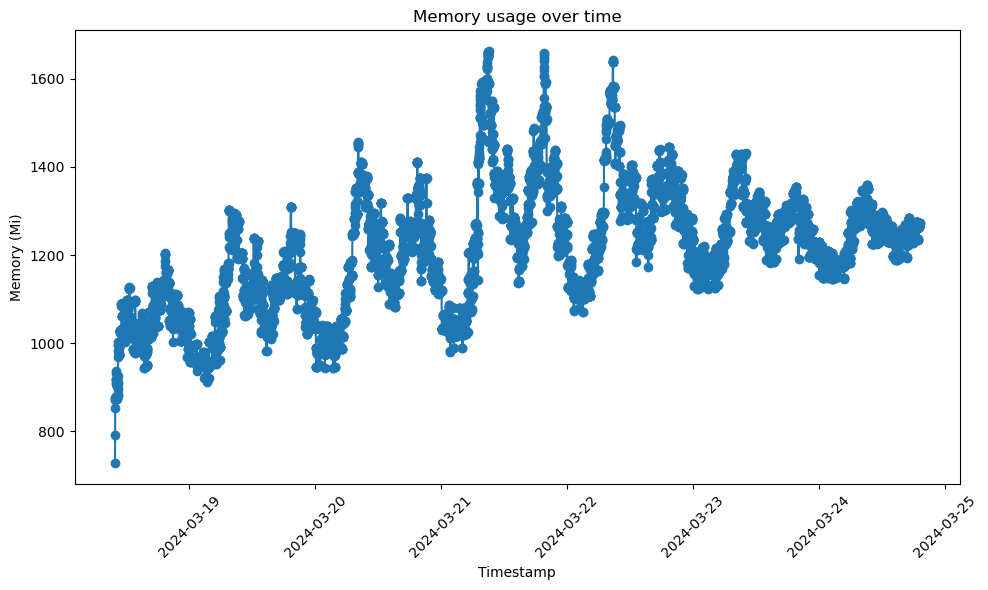

In [2]:
plt.figure(figsize=(10, 6))
plt.plot(node_stats.sort_values(by='Timestamp')['Timestamp'], node_stats['Memory'], marker='o', linestyle='-')
plt.title('Memory usage over time')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()

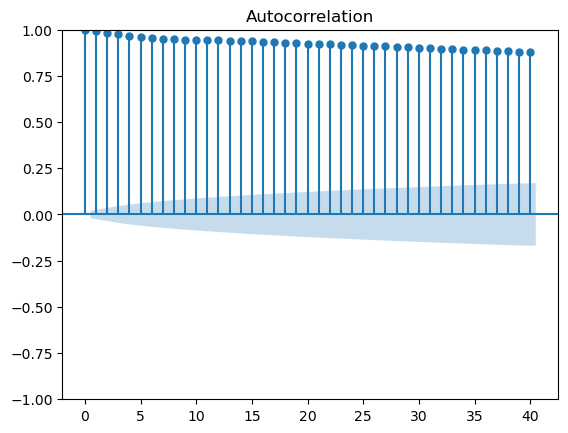

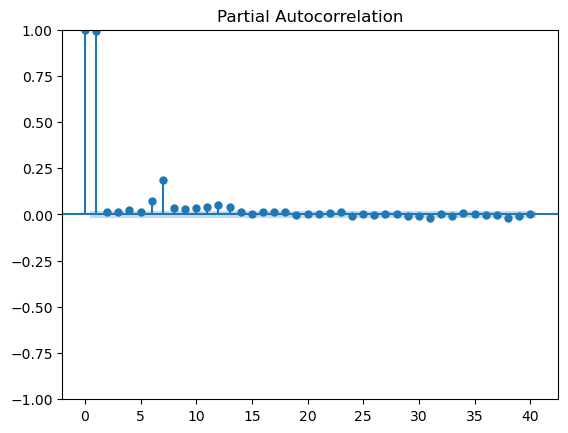

In [3]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
plot_acf(node_stats['Memory'], lags=40)
plot_pacf(node_stats['Memory'], lags=40)
plt.show()


<Axes: xlabel='Lag', ylabel='Autocorrelation'>

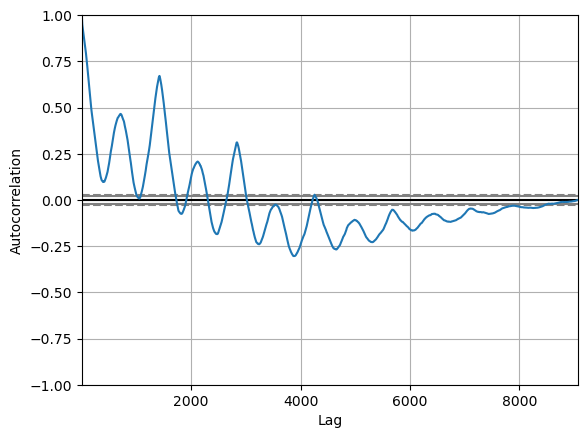

In [4]:
from pandas.plotting import autocorrelation_plot

autocorrelation_plot(node_stats['Memory'])


In [5]:
from statsmodels.tsa.arima.model import ARIMA

node_mem = node_stats[['Timestamp', 'Memory']]
node_mem = node_mem.set_index('Timestamp')
node_mem.index = node_mem.index.to_period('min')
node_mem

,Memory
Timestamp,
2024-03-18 09:48,728
2024-03-18 09:49,792
2024-03-18 09:50,854
2024-03-18 09:51,872
2024-03-18 09:52,875
...,...
2024-03-24 19:10,1273
2024-03-24 19:11,1272
2024-03-24 19:12,1271


In [6]:
arima_model = ARIMA(node_mem, order=(5,1,5))
arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                 Memory   No. Observations:                 9071
Model:                 ARIMA(5, 1, 5)   Log Likelihood              -38445.800
Date:                Tue, 30 Apr 2024   AIC                          76913.600
Time:                        22:12:25   BIC                          76991.840
Sample:                    03-18-2024   HQIC                         76940.213
                         - 03-24-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0647      0.067     15.937      0.000       0.934       1.196
ar.L2         -0.9286      0.115     -8.046      0.000      -1.155      -0.702
ar.L3          0.7098      0.122      5.808      0.0

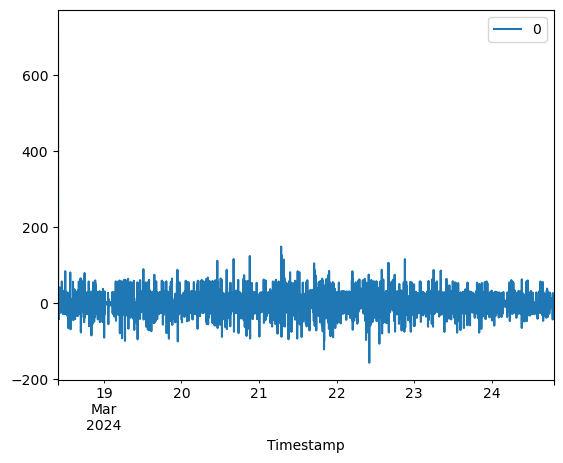

In [7]:
residuals = pd.DataFrame(arima_fit.resid)
residuals.plot()
plt.show()

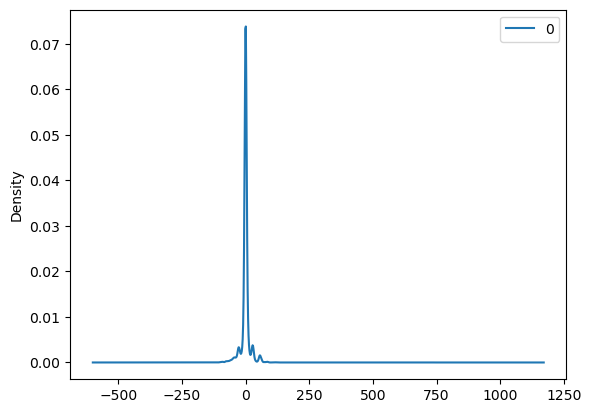

In [8]:
residuals.plot(kind='kde')
plt.show()

In [9]:
node_mem.describe()

,Memory
count,9071.000000
mean,1206.225223
std,136.287644
min,728.000000
25%,1110.000000
50%,1216.000000
75%,1291.000000
max,1663.000000


In [35]:
from sklearn.metrics import mean_squared_error

X_vals = node_mem.values
train_size = int(X_vals.shape[0] * 0.9)

X_train, X_test = X_vals[0:train_size], X_vals[train_size:X_vals.shape[0]]

history = [x for x in X_train]
predictions = list()

print("TOTAL ITER:", X_test.shape[0])

PRINT_EVERY = 100
for t in range(X_test.shape[0]):
    output = history[-1] 
    predictions.append(output[0])
    obs = X_test[t]
    history.append(obs)
    if t % PRINT_EVERY == 0:
        print('predicted=%f, expected=%f' % (output[0], obs))

rmse = np.sqrt(mean_squared_error(X_test, predictions))
print('Test RMSE: %.3f' % rmse)

TOTAL ITER: 908
predicted=1188.000000, expected=1187.000000
predicted=1251.000000, expected=1193.000000
predicted=1319.000000, expected=1318.000000
predicted=1320.000000, expected=1321.000000
predicted=1228.000000, expected=1229.000000
predicted=1265.000000, expected=1265.000000
predicted=1236.000000, expected=1236.000000
predicted=1255.000000, expected=1228.000000
predicted=1269.000000, expected=1267.000000
predicted=1264.000000, expected=1272.000000
Test RMSE: 11.979


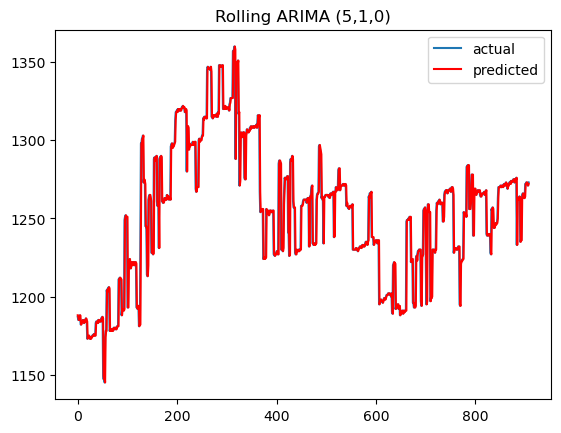

In [36]:
plt.plot(X_test, label='actual')
plt.plot(predictions, color='red', label='predicted')
plt.title("Rolling ARIMA (5,1,0)")
plt.legend()
plt.show()

In [12]:
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

X_vals = node_mem.iloc[::100].copy()
train_size = int(X_vals.shape[0] * 0.9)

X_train, X_test = X_vals.iloc[0:train_size], X_vals.iloc[train_size:X_vals.shape[0]]

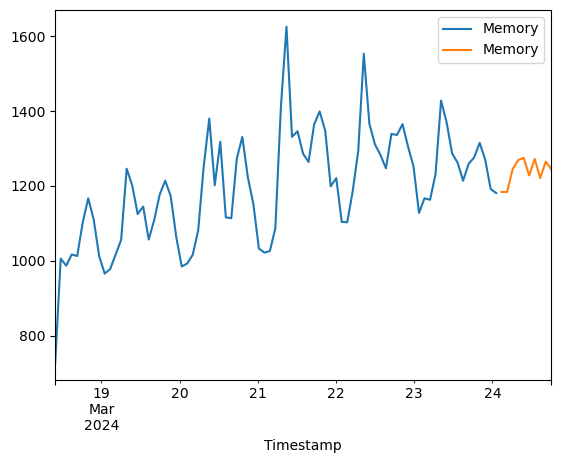

In [13]:
fig, ax = plt.subplots()
X_train.plot(ax=ax, label='train')
X_test.plot(ax=ax, label='test')
plt.legend()
plt.show()

In [14]:
adf_result = adfuller(X_train)
print('ADF Statistic: %f' % adf_result[0])
print('p-value: %f' % adf_result[1])

ADF Statistic: -2.229108
p-value: 0.195851


In [15]:
adf_result1 = adfuller(X_train.diff().dropna())
print('ADF Statistic: %f' % adf_result1[0])
print('p-value: %f' % adf_result1[1])

ADF Statistic: -8.080633
p-value: 0.000000


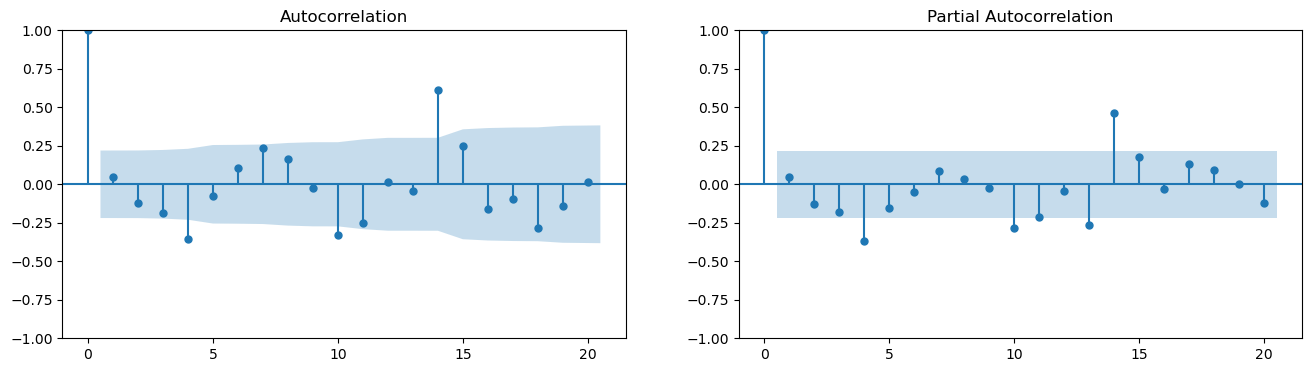

In [16]:
X_train_diff = X_train.diff().dropna()
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(X_train_diff, ax=ax[0])
plot_pacf(X_train_diff, ax=ax[1])
plt.show()

In [17]:
model = ARIMA(X_train, order=(15,1,15))
model_fit = model.fit()

predictions = model_fit.predict(start=X_test.index[0].to_timestamp(), end=X_test.index[-1].to_timestamp())
predictions = predictions.iloc[::100]
#rmse = np.sqrt(mean_squared_error(X_test, predictions))
#print('Test RMSE: %.3f' % rmse)

C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


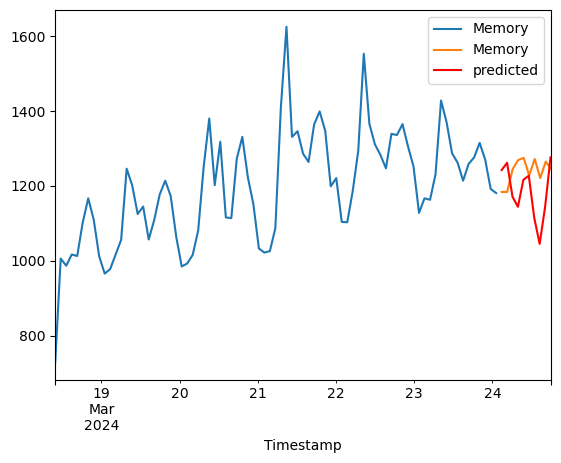

In [18]:
fig, ax = plt.subplots()
X_train.plot(ax=ax, label='train')
X_test.plot(ax=ax, label='actual')
predictions.plot(ax=ax, color='red', label='predicted')
plt.legend()
plt.show()

In [19]:
adf_result = adfuller(X_train)
print('ADF Statistic: %f' % adf_result[0])
print('p-value: %f' % adf_result[1])

ADF Statistic: -2.229108
p-value: 0.195851


In [20]:
adf_result1 = adfuller(X_train.diff(12).dropna())
print('ADF Statistic: %f' % adf_result1[0])
print('p-value: %f' % adf_result1[1])

ADF Statistic: -2.983984
p-value: 0.036417


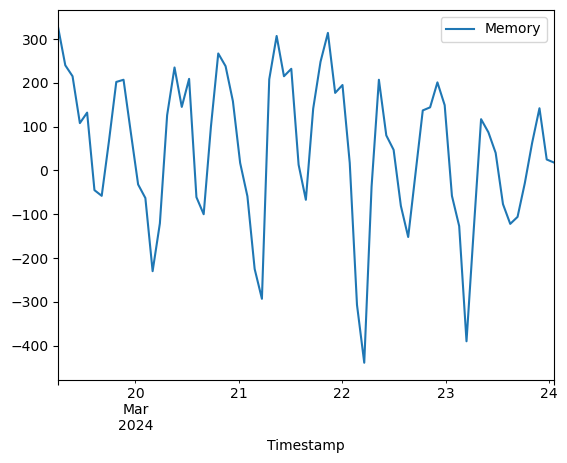

In [21]:
X_train_sdiff = X_train.diff(12).dropna()
fig, ax = plt.subplots()
X_train_sdiff.plot(ax=ax, label='train')
plt.legend()
plt.show()

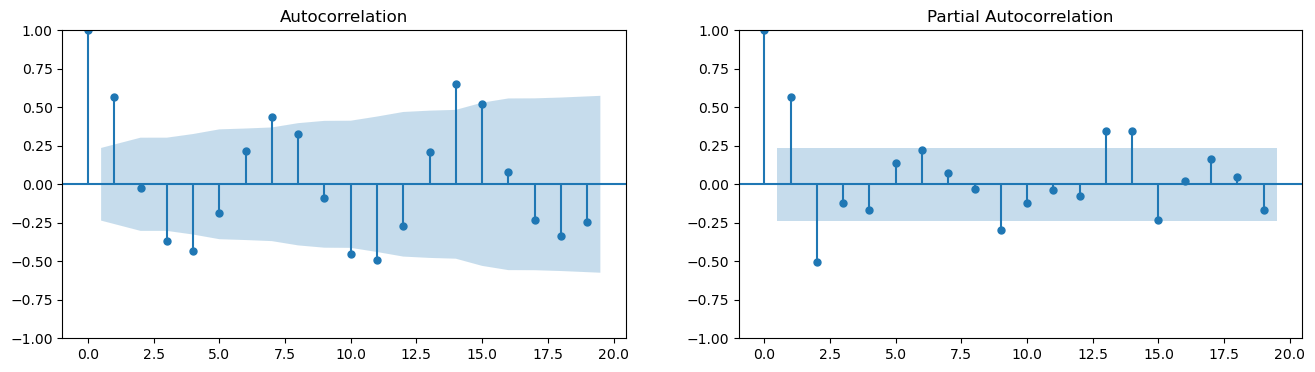

In [22]:
X_train_diff = X_train.diff(12).dropna()
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(X_train_diff, ax=ax[0])
plot_pacf(X_train_diff, ax=ax[1])
plt.show()

In [33]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(X_train, order=(0,1,15), seasonal_order=(15, 0, 0, 12))
model_fit = model.fit()

predictions = model_fit.predict(start=X_test.index[0].to_timestamp(), end=X_test.index[-1].to_timestamp())
predictions = predictions.iloc[::100]
#rmse = np.sqrt(mean_squared_error(X_test, predictions))
#print('Test RMSE: %.3f' % rmse)

C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


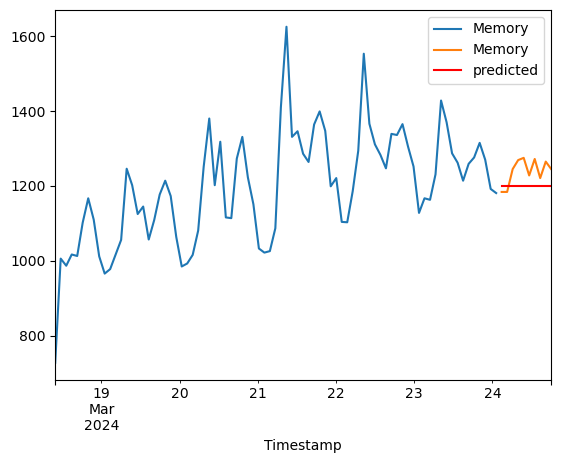

In [34]:
fig, ax = plt.subplots()
X_train.plot(ax=ax, label='train')
X_test.plot(ax=ax, label='actual')
predictions.plot(ax=ax, color='red', label='predicted')
plt.legend()
plt.show()